In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [3]:
data = torch.load("cached_clip_embeddings.pth", map_location=device)

val_embs   = data["embeddings"]["val"].to(device)
val_labels = data["labels"]["val"].view(-1).long().to(device)

print(val_embs.shape)
print(val_labels.shape)


torch.Size([10004, 512])
torch.Size([10004])


In [4]:
class LinearProbe(nn.Module):
    def __init__(self, in_dim, num_classes):
        super().__init__()
        self.fc = nn.Linear(in_dim, num_classes)

    def forward(self, x):
        return self.fc(x)

num_classes = len(torch.unique(val_labels))
model = LinearProbe(512, num_classes).to(device)


In [5]:
state_dict = torch.load("linear_probe_final.pth", map_location=device)
model.load_state_dict(state_dict)

model.eval()
print("Model loaded successfully")


Model loaded successfully


In [6]:
val_loader = DataLoader(
    TensorDataset(val_embs, val_labels),
    batch_size=128,
    shuffle=False
)


In [7]:
all_preds = []
all_targets = []

with torch.no_grad():
    for x, y in val_loader:
        logits = model(x)
        preds = torch.argmax(logits, dim=1)

        all_preds.append(preds.cpu())
        all_targets.append(y.cpu())

all_preds = torch.cat(all_preds).numpy()
all_targets = torch.cat(all_targets).numpy()


In [8]:
precision = precision_score(all_targets, all_preds, average="macro")
recall    = recall_score(all_targets, all_preds, average="macro")
f1        = f1_score(all_targets, all_preds, average="macro")

print(f"Precision: {precision*100:.2f}%")
print(f"Recall:    {recall*100:.2f}%")
print(f"F1-score:  {f1*100:.2f}%")

print("\nClassification Report:\n")
print(classification_report(all_targets, all_preds))


Precision: 91.45%
Recall:    91.44%
F1-score:  91.43%

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1041
           1       0.99      0.99      0.99      1057
           2       0.90      0.84      0.87      1152
           3       0.97      0.98      0.97      1156
           4       0.90      0.92      0.91       890
           5       0.90      0.89      0.90      1354
           6       0.89      0.88      0.89       877
           7       0.81      0.83      0.82      1045
           8       0.89      0.91      0.90      1432

    accuracy                           0.91     10004
   macro avg       0.91      0.91      0.91     10004
weighted avg       0.91      0.91      0.91     10004



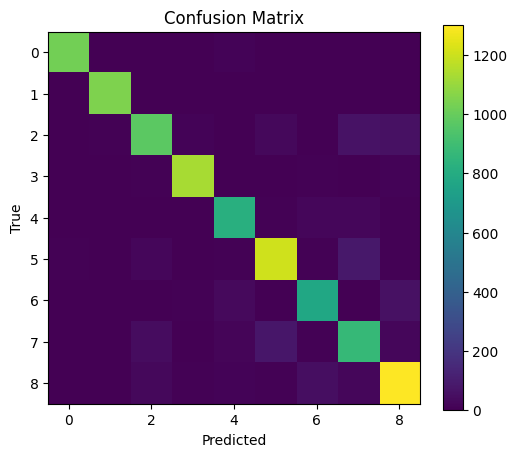

In [9]:
cm = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(6,5))
plt.imshow(cm)
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [10]:
class_acc = cm.diagonal() / cm.sum(axis=1) * 100

for i, acc in enumerate(class_acc):
    print(f"Class {i} Accuracy: {acc:.2f}%")


Class 0 Accuracy: 98.27%
Class 1 Accuracy: 99.43%
Class 2 Accuracy: 84.29%
Class 3 Accuracy: 97.84%
Class 4 Accuracy: 91.91%
Class 5 Accuracy: 89.07%
Class 6 Accuracy: 88.14%
Class 7 Accuracy: 83.25%
Class 8 Accuracy: 90.78%
